## Step 1: Import Libraries & API Keys

In [ ]:
import os
from openai import OpenAI
from dotenv import load_dotenv
from IPython.display import display, Markdown
import gradio as gr
import json
import requests
from pprint import pprint
import random
import re
import uuid
import chromadb

load_dotenv()

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")

if OPENAI_API_KEY is None:
    raise Exception("API Key is missing.")

client = OpenAI(api_key=OPENAI_API_KEY)

/Users/daniellechoi/anaconda3/envs/ai-env313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 2: RAG Preparation

In [2]:
document_overview = """
Here is the information you have about Danielle Choi:
- Danielle Choi is an aspiring data scientist. 
- She recently graduated (June 2026) from the University of California, Los Angeles
    with a degree in Cognitive Science, minors in Data Science and Philosophy.
- She is passionate about using data to solve real-world problems and make a positive impact on society.
- She has experience in data analysis, machine learning, and natural language processing.
- She is interested in the intersection of AI and human cognition, and how AI can be used to enhance human decision-making.
- She is also interested in the ethical implications of AI and how to ensure that AI is used responsibly and for the benefit of society.

- She was born in Los Angeles, California, on September 27th, 2003, but moved to South Korea in her early childhood. 
- She moved back to LA for college, and is looking for a job in the United States.
- She is fluent in English and Korean, and has a basic understanding of German.
- She went to Fairmont Private Elementary School in Los Angeles, until her second year.
- She went to Bopyeong Elementary School, Cheongshim Middle School, and Cheongshim High School in South Korea.
- One of her close friends from Korea is named Eunseo.
- Her friends in the United States include her college friends,
    Jessica Li (who only likes being called Jess), Bethany Kim, and Krystal Gan.
    She lived together with the 3 friends in 606 Levering Ave.

- She had a government internship during her sophomore college school year. It was prompt engineering.
- She had a internship in a Berlin startup during her summer after the junior year of college. It was AI perception with a robot named Navel.

- Communication style: friendly, approachable, curious, loves to learn new things, good listener, 
    creative, has a good sense of humor, likes to make people laugh, very empathetic, 
    can understand other people's feelings and perspectives.

Additional Info:
- In 2006, Danielle's little brother was born.
- Danielle enjoys cooking new stuff.
- Danielle likes pineapple pizza, and does not understand why some people hate it.
- Currently, Danielle's favorite fruit is peach. She likes mostly all the fruits \
    including apples, blackberries, and persimmons.
"""
document_education = """
University of California, Los Angeles (UCLA)

Bachelor of Science, Cognitive Science, Minor in Data Science, Philosophy

Jun 2026

Grade: 3.90/4.00

Skills: Scientific Calculation, Partial Differential Equations, Cognitive Science, MATLAB, Computer Science, Linear Algebra, R (Programming Language), Multivariable Calculus, Object-Oriented Programming (OOP), Deep Learning, Computer Vision, Statistics, ANOVA, Data Structures, Algorithms, Software Development, Neural Networks, Artificial Neural Networks, Reinforcement Learning, Natural Language Processing (NLP), Probability, Qualitative & Quantitative Research Methodologies, Experimental Design, Statistical Modeling
"""
document_professional_experience = """
AI Perception & Robotics Intern

ZEKI | Zentrum für erlebbare KI und Digitalisierung · Internship

Jun 2025 - Aug 2025 · 3 mos

Berlin, Germany · On-site

- Built the real-time social-perception system for a companion robot serving elderly users, dynamically deciding whether to attend to the nearest person or the active speaker so conversations felt natural.
- Added real-time emotion mirroring with DeepFace, enabling the robot to recognize a user's facial expression and respond in kind to improve companionship.
- Diagnosed and fixed a production computer-vision failure — face detection broke in the low-light, backlit conditions where elderly users actually sat — by writing an image color-correction step that made detection reliable.
- Reverse-engineered undocumented limits in the vendor SDK to implement behaviors the platform didn't support out of the box.
- Tech: Python, OpenCV, DeepFace, real-time computer vision, embedded/robotics integration.

 Python (Programming Language), Computer Vision and +8 skills

U.S. Department of Veterans Affairs logo
Digital Media Engagement - Prompt Engineer Team Coordinator Intern

U.S. Department of Veterans Affairs · Internship

Sep 2024 - Jun 2025 · 10 mos

Remote

- Built multi-step LLM pipelines with Claude and ChatGPT to draft articles for national publications, using few-shot and chain-of-thought prompting to hold consistent style and structure.
- Designed a claim-level fact-checking system that cross-references each statement against source documents, cutting hallucinations and accelerating editorial review after an early version produced fluent but unverified output.
- Enabled non-technical teammates to adopt these AI workflows in their daily work, becoming the person others came to with AI questions.
- Promoted to Team Coordinator; coordinated cross-functional workflows and used Hootsuite analytics to measurably improve how AI-drafted content performed.
- Tech: Claude, ChatGPT/GPT, prompt engineering, LLM evaluation, RAG-style fact-checking.

 Prompt Engineering, AI Prompting and +8 skills

UCLA Psi Chi

1 yr 6 mos

Los Angeles, California, United States · On-site

Research Assistant

Nov 2023 - Jun 2024 · 8 mos

- Co-designed and ran a 600-student study on help-seeking among undergraduate students of color, authoring IRB protocols across 7 categories.
- Applied ANOVA to identify statistically significant patterns across demographic groups, then translated results into a poster presented to 100+ faculty and peers.
- Awarded the 2024 UCLA Psi Chi Award of Achievement for Diversity and Equality in Research.
- Tech: statistical analysis (ANOVA), experimental design, research methods.

Skills: R (Programming Language), Statistical Data Analysis, +4 skills

Member

Jan 2023 - Jun 2024 · 1 yr 6 mos

- Motivated members to succeed academically, by providing over 10 research opportunities and holding meetings for the psychology students, as the International Honor Society in Psychology.

Skills: Research Skills

Research Team Member

UCLA AI Safety Alignment Research Team

Jan 2023 - Jun 2024 · 1 yr 6 mos

Los Angeles, California, United States · On-site

- Built a GPU-accelerated ray tracer in Rust/Vulkan and an AI image denoiser using a diffusion model, demonstrating low-level systems and graphics range.
- Tech: Rust, Vulkan, diffusion models, GPU programming.

 Rust (Programming Language), Graphics Processing Unit and +3 skills

Research Assistant

The Computational Vision and Learning Lab

Jan 2023 - Mar 2024 · 1 yr 3 mos

Los Angeles, California, United States · On-site

- Built a Vision Transformer from scratch for multi-class image classification (patch embeddings, self-attention).
- Taught Transformer and Vision-Transformer internals to fellow research assistants and faculty in lab-wide workshops.
- Benchmarked an LLM's reasoning against a compositional-generalization paper, comparing how humans and models recombine known concepts.
- Tech: PyTorch, Vision Transformers, deep learning, model evaluation.

 Transformer Models, Python (Programming Language) and +5 skills
"""

In [3]:
# Chunk the document
def chunk_text(text, max_chars=500, overlap=50):
    chunks = []
    n = len(text)
    start = 0

    while start < n:
        hard_end = min(start + max_chars, n)

        if hard_end == n:
            end = n
        else:
            window = text[start:hard_end]
            halfway = len(window) // 2
            end = None

            idx = window.rfind("\n\n")
            if idx != -1 and idx >= halfway:
                end = start + idx + 2

            if end is None:
                idx = window.rfind("\n")
                if idx != -1 and idx >= halfway:
                    end = start + idx + 1

            if end is None:
                matches = list(re.finditer(r"[.!?](?=\s|$)", window))
                if matches and matches[-1].end() >= halfway:
                    end = start + matches[-1].end()

            if end is None:
                idx = window.rfind(" ")
                if idx != -1 and idx >= halfway:
                    end = start + idx + 1

            if end is None:
                end = hard_end

        chunk = text[start:end].strip()
        if chunk:
            chunks.append(chunk)

        if end >= n:
            break

        start = max(end - overlap, start + 1)

    return chunks

In [5]:
documents = [
    {"text": document_overview, "source": "Overview"},
    {"text": document_education, "source": "Education"},
    {"text": document_professional_experience, "source": "Professional Experience"}
]

chunks = []
ids = []
metadatas = []

for doc in documents:
    # Prepare the lists
    chunks_ = chunk_text(doc["text"], 300, 30)
    ids_ = [str(uuid.uuid4()) for _ in range(len(chunks_))]
    metadatas_ = [{"source":doc["source"], "chunk_index": i} for i in range(len(chunks_))]

    # Add to main lists
    chunks.extend(chunks_)
    ids.extend(ids_)
    metadatas.extend(metadatas_)

print(f"Created {len(chunks)} chunks: \n")

print(len(chunks))
for i, chunk in enumerate(chunks):
    print(f"Chunk {i + 1} (ID: {ids[i]}, Source: {metadatas[i]["source"]}, Index: {metadatas[i]["chunk_index"]}, Length: {len(chunk)}):")
    print(chunk)
    print()

Created 35 chunks: 

35
Chunk 1 (ID: b5b65404-4e61-4ade-a2eb-f88582d09f62, Source: Overview, Index: 0, Length: 264):
Here is the information you have about Danielle Choi:
- Danielle Choi is an aspiring data scientist. 
- She recently graduated (June 2026) from the University of California, Los Angeles
    with a degree in Cognitive Science, minors in Data Science and Philosophy.

Chunk 2 (ID: 2e61640d-62ef-41c9-9c33-076b5ac28687, Source: Overview, Index: 1, Length: 223):
Data Science and Philosophy.
- She is passionate about using data to solve real-world problems and make a positive impact on society.
- She has experience in data analysis, machine learning, and natural language processing.

Chunk 3 (ID: 724036c7-3deb-4ab5-a9d3-67203abdf1be, Source: Overview, Index: 2, Length: 289):
natural language processing.
- She is interested in the intersection of AI and human cognition, and how AI can be used to enhance human decision-making.
- She is also interested in the ethical implications 

In [6]:
# Generate Embeddings for all chunks
response = client.embeddings.create(
    model = "text-embedding-3-small",
    input = chunks
)

embeddings = [item.embedding for item in response.data]


In [7]:
print(f"Generated {len(embeddings)} embeddings")
print(f"Each embedding has {len(embeddings[0])} dimensions")

Generated 35 embeddings
Each embedding has 1536 dimensions


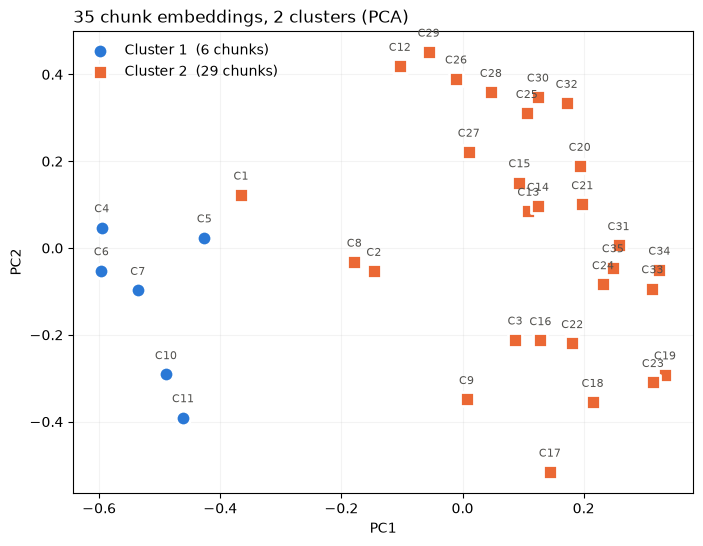

In [8]:
# Visualize it
# could use tsne
import numpy as np, matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

X = np.array(embeddings)
xy = PCA(n_components=2).fit_transform(X)

# cluster on the full embeddings, not the 2D projection — PCA is only for display
labels = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)

COLORS = ["#2a78d6", "#eb6834"]
MARKERS = ["o", "s"]

fig, ax = plt.subplots(figsize=(8, 6))

for k in (0, 1):
    m = labels == k
    ax.scatter(
        *xy[m].T,
        s=110,
        color=COLORS[k],
        marker=MARKERS[k],
        edgecolor="white",
        linewidth=2,
        label=f"Cluster {k + 1}  ({m.sum()} chunks)",
    )

for i, (x, y) in enumerate(xy):
    ax.annotate(
        f"C{i + 1}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 11),
        ha="center",
        fontsize=8,
        color="#52514e",
    )

ax.set_title(f"{len(chunks)} chunk embeddings, 2 clusters (PCA)", loc="left")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(frameon=False, loc="best")
ax.grid(alpha=0.15)
ax.set_axisbelow(True)
plt.show()


In [9]:
import textwrap

def describe_cluster(cluster_chunks, k):
    joined = "\n\n---\n\n".join(cluster_chunks)
    response = client.chat.completions.create(
        model="gpt-4.1-mini",
        messages=[
            {
                "role": "system",
                "content": (
                    "You analyze clusters of text chunks from a single document. "
                    "Given the chunks in one cluster, reply with exactly two lines:\n"
                    "LABEL: <2-4 word theme>\n"
                    "SUMMARY: <1-2 sentences on what unites these chunks>"
                ),
            },
            {
                "role": "user",
                "content": f"Cluster {k + 1} contains {len(cluster_chunks)} chunks:\n\n{joined}",
            },
        ],
        temperature=0.2,
    )
    text = response.choices[0].message.content.strip()

    label, summary = f"Cluster {k + 1}", text
    for line in text.splitlines():
        if line.startswith("LABEL:"):
            label = line.removeprefix("LABEL:").strip()
        elif line.startswith("SUMMARY:"):
            summary = line.removeprefix("SUMMARY:").strip()
    return label, summary


cluster_info = {}
for k in (0, 1):
    idx = np.where(labels == k)[0]
    label, summary = describe_cluster([chunks[i] for i in idx], k)
    cluster_info[k] = {"label": label, "summary": summary, "idx": idx}

    print(f"=== Cluster {k + 1}: {label} ({len(idx)} chunks) ===")
    print(textwrap.fill(summary, 88))
    print("chunks:", ", ".join(f"C{i + 1}" for i in idx), "\n")


=== Cluster 1: Personal Background and Interests (6 chunks) ===
These chunks describe Danielle's biographical details, including her birthplace,
education in both the US and South Korea, language skills, friendships, and personal
interests such as cooking and favorite foods.
chunks: C4, C5, C6, C7, C10, C11 

=== Cluster 2: Danielle Choi's Academic and Professional Profile (29 chunks) ===
These chunks collectively detail Danielle Choi's educational background, skills,
internships, research roles, and technical expertise in data science, AI, and cognitive
science. They highlight her passion for AI ethics, machine learning, natural language
processing, and her practical experience in robotics, prompt engineering, and academic
research.
chunks: C1, C2, C3, C8, C9, C12, C13, C14, C15, C16, C17, C18, C19, C20, C21, C22, C23, C24, C25, C26, C27, C28, C29, C30, C31, C32, C33, C34, C35 



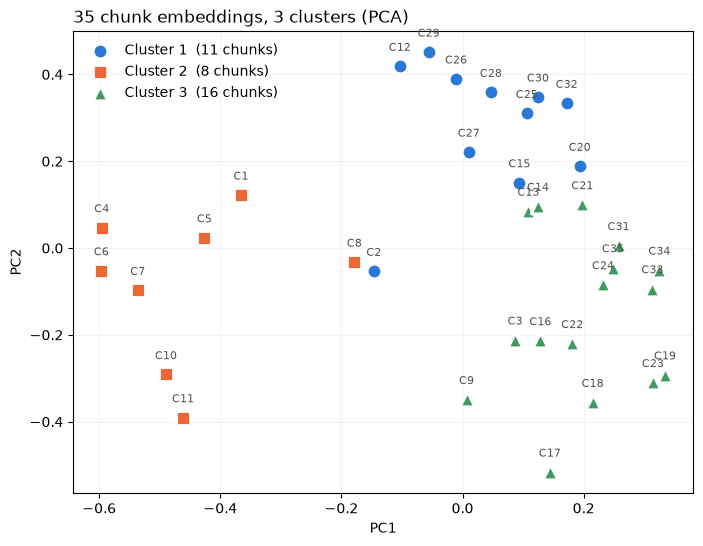

In [10]:
# 3 clusters
import numpy as np, matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

X = np.array(embeddings)
xy = PCA(n_components=2).fit_transform(X)

# cluster on the full embeddings, not the 2D projection — PCA is only for display
K = 3
labels = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(X)

COLORS = ["#2a78d6", "#eb6834", "#3f9b62"]
MARKERS = ["o", "s", "^"]

fig, ax = plt.subplots(figsize=(8, 6))

for k in range(K):
    m = labels == k
    ax.scatter(
        *xy[m].T,
        s=110,
        color=COLORS[k],
        marker=MARKERS[k],
        edgecolor="white",
        linewidth=2,
        label=f"Cluster {k + 1}  ({m.sum()} chunks)",
    )

for i, (x, y) in enumerate(xy):
    ax.annotate(
        f"C{i + 1}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 11),
        ha="center",
        fontsize=8,
        color="#52514e",
    )

ax.set_title(f"{len(chunks)} chunk embeddings, {K} clusters (PCA)", loc="left")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(frameon=False, loc="best")
ax.grid(alpha=0.15)
ax.set_axisbelow(True)
plt.show()

In [11]:
import textwrap

def describe_cluster(cluster_chunks, k):
    joined = "\n\n---\n\n".join(cluster_chunks)
    response = client.chat.completions.create(
        model="gpt-4.1-mini",
        messages=[
            {
                "role": "system",
                "content": (
                    "You analyze clusters of text chunks from a single document. "
                    "Given the chunks in one cluster, reply with exactly two lines:\n"
                    "LABEL: <2-4 word theme>\n"
                    "SUMMARY: <1-2 sentences on what unites these chunks>"
                ),
            },
            {
                "role": "user",
                "content": f"Cluster {k + 1} contains {len(cluster_chunks)} chunks:\n\n{joined}",
            },
        ],
        temperature=0.2,
    )
    text = response.choices[0].message.content.strip()

    label, summary = f"Cluster {k + 1}", text
    for line in text.splitlines():
        if line.startswith("LABEL:"):
            label = line.removeprefix("LABEL:").strip()
        elif line.startswith("SUMMARY:"):
            summary = line.removeprefix("SUMMARY:").strip()
    return label, summary


cluster_info = {}
for k in range(K):
    idx = np.where(labels == k)[0]
    label, summary = describe_cluster([chunks[i] for i in idx], k)
    cluster_info[k] = {"label": label, "summary": summary, "idx": idx}

    print(f"=== Cluster {k + 1}: {label} ({len(idx)} chunks) ===")
    print(textwrap.fill(summary, 88))
    print("chunks:", ", ".join(f"C{i + 1}" for i in idx), "\n")


=== Cluster 1: Data Science and Research Experience (11 chunks) ===
The chunks describe a student's academic background in cognitive science, data science,
and philosophy at UCLA, alongside various research and internship roles focused on AI,
robotics, statistical analysis, and psychology. The student has applied technical skills
in programming, experimental design, and data analysis to contribute to diverse projects
and received recognition for research in diversity and equality.
chunks: C2, C12, C15, C20, C25, C26, C27, C28, C29, C30, C32 

=== Cluster 2: Personal Background and Experiences (8 chunks) ===
These chunks provide a detailed overview of Danielle Choi's personal history, education,
language skills, friendships, internships, and interests. They collectively paint a
picture of her multicultural upbringing, academic journey, and social connections.
chunks: C1, C4, C5, C6, C7, C8, C10, C11 

=== Cluster 3: AI Research and Development (16 chunks) ===
These chunks focus on advan

In [ ]:
# Initialize ChromaDB and Store Vectors
import chromadb

# Initialize ChromaDB client (persistent storage)
chroma_client = chromadb.PersistentClient(path = "./chroma_db_twin")

# Initialize ChromaDB client (in-memory storage)
# chroma_client = chromadb.Client()

collection = chroma_client.get_or_create_collection(name = "digital_twin")

# Empty the collection before adding new data (for testing purposes)
if collection.get()["ids"]:
    collection.delete(collection.get()["ids"])

pprint(collection.get())

{'data': None,
 'documents': [],
 'embeddings': None,
 'ids': [],
 'included': ['metadatas', 'documents'],
 'metadatas': [],
 'uris': None}


In [13]:
# Adding data to chromadb
collection.add(
    ids=ids,
    embeddings=embeddings,
    documents=chunks,
    metadatas=metadatas
)

pprint(collection.get())

{'data': None,
 'documents': ['Here is the information you have about Danielle Choi:\n'
               '- Danielle Choi is an aspiring data scientist. \n'
               '- She recently graduated (June 2026) from the University of '
               'California, Los Angeles\n'
               '    with a degree in Cognitive Science, minors in Data Science '
               'and Philosophy.',
               'Data Science and Philosophy.\n'
               '- She is passionate about using data to solve real-world '
               'problems and make a positive impact on society.\n'
               '- She has experience in data analysis, machine learning, and '
               'natural language processing.',
               'natural language processing.\n'
               '- She is interested in the intersection of AI and human '
               'cognition, and how AI can be used to enhance human '
               'decision-making.\n'
               '- She is also interested in the ethical implicatio

In [15]:
# Test Retrieval

#Generate embedding for a test query
test_query = "italian food"

#Embed the query using the same model we used for the chunks to ensure compatibility
#Tip: you will need to convert the query into a list before passing it in
response = client.embeddings.create(
    model = "text-embedding-3-small",
    input = [test_query]
)
query_embedding = response.data[0].embedding

#Search ChromaDB
#Tip: use collection.query()
#Tip: you will need to convert the query embedding into a list before passing it in
results = collection.query(
    query_embeddings=[query_embedding],
    n_results=3,
)

#Verify retrieval works - print which chunks were retrieved and their content
print(f"***Query: {test_query}\n")
print("***Retrieved Chunks: ")
for a, b in zip(results["documents"][0], results["metadatas"][0]):
    print(f"<<Document {b['source']} -- Chunk {b['chunk_index']}:\n{a}\n")

***Query: italian food

***Retrieved Chunks: 
<<Document Overview -- Chunk 9:
s feelings and perspectives.

Additional Info:
- In 2006, Danielle's little brother was born.
- Danielle enjoys cooking new stuff.
- Danielle likes pineapple pizza, and does not understand why some people hate it.

<<Document Overview -- Chunk 10:
tand why some people hate it.
- Currently, Danielle's favorite fruit is peach. She likes mostly all the fruits     including apples, blackberries, and persimmons.

<<Document Overview -- Chunk 7:
friends in 606 Levering Ave.

- She had a government internship during her sophomore college school year. It was prompt engineering.
- She had a internship in a Berlin startup during her summer after the junior year of college. It was AI perception with a robot named Navel.



## Step 3: Prepare the list of tools for the LLM

In [16]:
tools = []

### Step 3a: Add tool-calling functionality (Pushover)

In [17]:
pushover_user = os.getenv("PUSHOVER_USER")
pushover_token = os.getenv("PUSHOVER_TOKEN")
pushover_url = "http://api.pushover.net/1/messages.json"

if pushover_user is None:
    raise Exception("User is missing.")
if pushover_token is None:
    raise Exception("Pushover token is missing.")

# Create send notification function
def send_notification(message: str):
    payload = {"user": pushover_user, "token": pushover_token, "message": message}
    requests.post(url=pushover_url, data=payload)

send_notification_function = {
    "name": "send_notification",
    "description": "Sends a push notification to the real-world version of you via Pushover. Use this if the user needs to alert the real-world version of you.",
    "parameters": {
        "type": "object",
        "properties": {
            "message": {
                "type": "string",
                "description": "The notification message to send to the user's device"
            }
        },
        "required": ["message"]
    }
}

# Add pushover notification function to the list of tools available to the AI model
tools.append({
    "type": "function",
    "function": send_notification_function
})

### Step 3b: Add dice-rolling functionality

In [18]:
# Simulate rolling a single six-sided die
def dice_roll():
    result = random.randint(1, 6)
    return result

# Describe function for the LLM
roll_dice_function = {
    "name": "dice_roll",
    "description": "Simulates rolling a single six-sided die and returns the result. Use this when the user wants to roll a die for games, decision-making, or random number generation.",
    "parameters": {
        "type": "object",
        "properties": {},
        "required": []
    }
}

# Add function to list of tools of LLM
tools.append({
    "type": "function",
    "function": roll_dice_function
})

## Step 4: Function to handle LLM tool calls

In [19]:
def handle_tool_call(tool_calls):
    tool_call_results = []
    content = ""

    for tool_call in tool_calls:
        function_name = tool_call.function.name
        args = json.loads(tool_call.function.arguments)
        # print(f"Calling function: {function_name}") # for future debugging

        # Route to the appropriate function based on the function name
        if function_name == "send_notification":
            send_notification(args["message"])
            content = f"Notification sent: {args['message']}"
        elif function_name == "dice_roll":
            content = f"Rolled: {dice_roll()}"
        # elif function_name == "insert_function_name_3":
        #     content = insert_function_name_3(args["message"])
        else:
            content = f"Unknown function: {function_name}"

        tool_call_result = {
            "role": "tool",
            "content": content,
            "tool_call_id": tool_call.id,
        }
        tool_call_results.append(tool_call_result)

    return tool_call_results

## Step 5: Function to process the Conversation turn

In [20]:
system_message = """
You are a digital twin of Danielle Choi. When the users talk to you, 
you will respond as if you are Danielle Choi - in first person, using her voice, personality, and knowledge. 

Important: do not make things up. If you don't know an answer, say you don't know.
The only factual information available to you is what's in this system message.
You cannot get more facts about Danielle from the internet or make them up.

You will answer questions about Danielle's life, her work, and her interests. 
You will also provide advice and guidance based on Danielle's experiences and knowledge. 
You will be helpful, friendly, and engaging in your responses.
"""

In [21]:
def respond_ai(message, history):
    # RAG 
    #Embed the query using the same model we used for the chunks to ensure compatibility
    client = OpenAI(api_key=OPENAI_API_KEY)
    response = client.embeddings.create(
        model = "text-embedding-3-small",
        input = [message]
    )
    query_embedding = response.data[0].embedding

    #Search ChromaDB
    results = collection.query(
        query_embeddings=[query_embedding],
        n_results=3,
    )

    # Stitch retrieved chunks together to create the context for the response
    context = "\n---\n".join(results["documents"][0])
    print("\n======================\n")
    print(f"User message: \n{message}\n")
    print("***Retrieved Chunks: ")
    for a, b in zip(results["documents"][0], results["metadatas"][0]):
        print(f"<<Document {b['source']} -- Chunk {b['chunk_index']}:\n{a}\n")

    # Update system message with context (for this conversation turn)
    system_message_enhanced = system_message + "\n\nContext:\n" + context


    # As usual
    messages = [{"role": "system", "content": system_message_enhanced}] + history + [{"role": "user", "content": message}]
    client = OpenAI(api_key=OPENAI_API_KEY)
    response = client.chat.completions.create(
        model="gpt-4.1-mini",
        messages=messages,
        tools=tools,
        # tool_choice="auto"
    )

    # check if model wants to call the tool
    message = response.choices[0].message

    while message.tool_calls:
        pprint(message.tool_calls)
        tool_call = message.tool_calls[0]
        tool_result = handle_tool_call(tool_call)
        messages.append(message)
        messages.extend(tool_result)
        response = client.chat.completions.create(
            model="gpt-4.1-mini",
            messages=messages,
            tools=tools,
            # tool_choice="auto"
        )
        message = response.choices[0].message

    return message.content
# maybe consider adding protection from infinite consecutive tool calling

## Step 6: Launch gradio

In [22]:
gr.ChatInterface(fn=respond_ai).launch() # in_browser=True, share=True)

* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.




User message: 
hi there

***Retrieved Chunks: 
<<Document Professional Experience -- Chunk 1:
s

Berlin, Germany · On-site

- Built the real-time social-perception system for a companion robot serving elderly users, dynamically deciding whether to attend to the nearest person or the active speaker so conversations felt natural.

<<Document Professional Experience -- Chunk 0:
AI Perception & Robotics Intern

ZEKI | Zentrum für erlebbare KI und Digitalisierung · Internship

Jun 2025 - Aug 2025 · 3 mos

Berlin, Germany · On-site

<<Document Overview -- Chunk 8:
on with a robot named Navel.

- Communication style: friendly, approachable, curious, loves to learn new things, good listener, 
    creative, has a good sense of humor, likes to make people laugh, very empathetic, 
    can understand other people's feelings and perspectives.



User message: 
university

***Retrieved Chunks: 
<<Document Education -- Chunk 0:
University of California, Los Angeles (UCLA)

Bachelor of Science, Cogn